In [1]:
# --- Section 1: Setup & configuration ---
import os, glob, random, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib

RANDOM_STATE = 42
random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)

TARGET_CLASSES = ['angry', 'happy', 'sad', 'neutral']
CLASS_TO_IDX = {c: i for i, c in enumerate(TARGET_CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

SAMPLES_PER_CLASS = 3000          # fast test: 1000 · best accuracy: up to ~3900
IMG_SIZE = (48, 48)
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8),
                  cells_per_block=(2, 2), block_norm='L2-Hys')

print("Config loaded. Classes:", TARGET_CLASSES, "| samples/class:", SAMPLES_PER_CLASS)

Config loaded. Classes: ['angry', 'happy', 'sad', 'neutral'] | samples/class: 3000


In [2]:
# --- Section 2a: Download data from Kaggle ---
from google.colab import files
print("Click 'Choose Files' below and select your kaggle.json ...")
files.upload()                      # a file-picker button appears — pick kaggle.json

!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d msambare/fer2013 -q
!unzip -q -o fer2013.zip -d fer2013_data

print("Done downloading & unzipping.")

Click 'Choose Files' below and select your kaggle.json ...


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/msambare/fer2013
License(s): DbCL-1.0
Done downloading & unzipping.


In [3]:
# --- Section 2b: Locate train/ and test/ folders ---
def find_data_dir(root='fer2013_data'):
    for dirpath, dirnames, _ in os.walk(root):
        if 'train' in dirnames and 'test' in dirnames:
            return dirpath
    raise FileNotFoundError("Could not locate train/ and test/ under " + root)

DATA_DIR  = find_data_dir()
TRAIN_DIR = os.path.join(DATA_DIR, 'train')
TEST_DIR  = os.path.join(DATA_DIR, 'test')
print("DATA_DIR:", DATA_DIR)
print("Train subfolders:", sorted(os.listdir(TRAIN_DIR)))

DATA_DIR: fer2013_data
Train subfolders: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [4]:
# --- Section 3: Load & filter images ---
def load_split(split_dir, per_class=None):
    images, labels = [], []
    for cls in TARGET_CLASSES:
        paths = glob.glob(os.path.join(split_dir, cls, '*'))
        if per_class is not None and len(paths) > per_class:
            paths = random.sample(paths, per_class)        # balanced subsample
        for p in paths:
            img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            if img.shape != IMG_SIZE:
                img = cv2.resize(img, IMG_SIZE)
            images.append(img); labels.append(CLASS_TO_IDX[cls])
    return np.array(images), np.array(labels)

X_train_img, y_train = load_split(TRAIN_DIR, per_class=SAMPLES_PER_CLASS)
X_test_img,  y_test  = load_split(TEST_DIR,  per_class=None)
print("Train:", X_train_img.shape, "Test:", X_test_img.shape)

Train: (12000, 48, 48) Test: (5212, 48, 48)


In [5]:
# Safety check: only our 4 classes, all present, balanced
assert set(np.unique(y_train)).issubset(set(IDX_TO_CLASS)), "Unexpected label leaked in"
assert set(np.unique(y_train)) == set(range(len(TARGET_CLASSES))), "A class is missing from train"
counts = pd.Series(y_train).map(IDX_TO_CLASS).value_counts()
print(counts)

angry      3000
happy      3000
sad        3000
neutral    3000
Name: count, dtype: int64


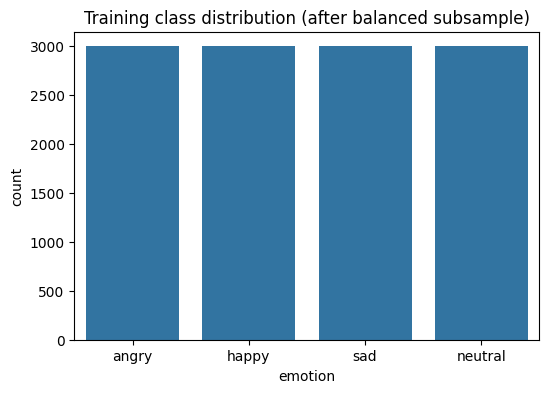

In [6]:
# --- Section 4a: Class distribution ---
plt.figure(figsize=(6,4))
sns.countplot(x=pd.Series(y_train).map(IDX_TO_CLASS), order=TARGET_CLASSES)
plt.title("Training class distribution (after balanced subsample)")
plt.xlabel("emotion"); plt.show()

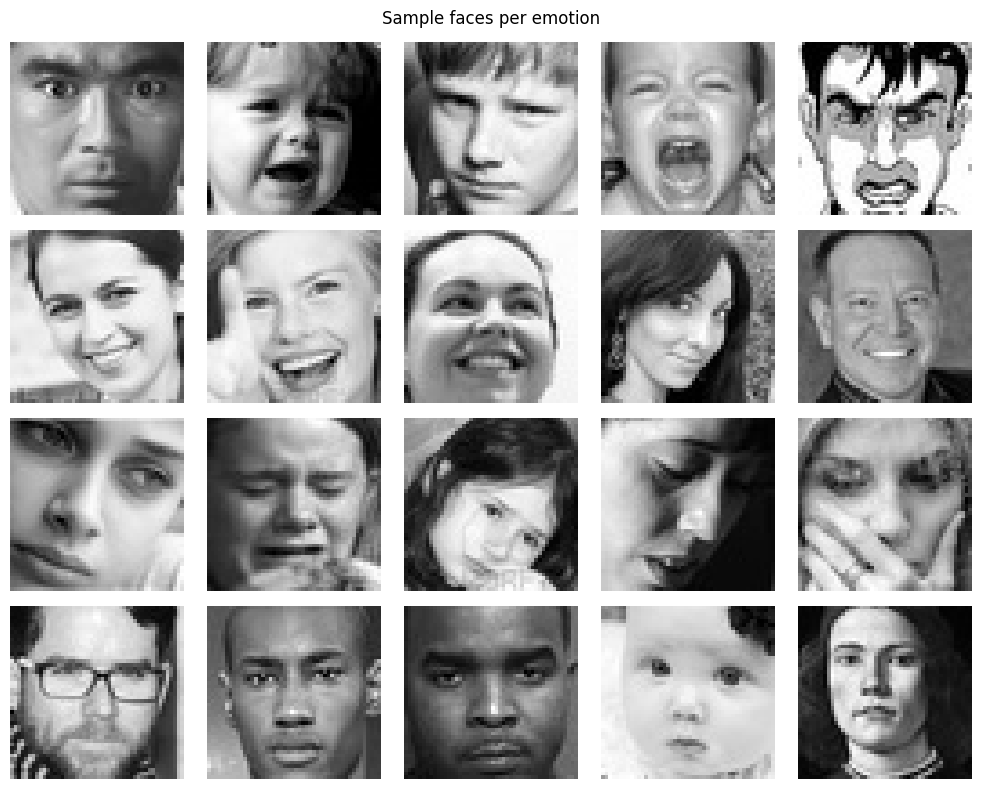

In [7]:
# --- Section 4b: Sample faces per emotion ---
fig, axes = plt.subplots(len(TARGET_CLASSES), 5, figsize=(10, 8))
for r, cls in enumerate(TARGET_CLASSES):
    idx = np.where(y_train == CLASS_TO_IDX[cls])[0][:5]
    for c, i in enumerate(idx):
        axes[r, c].imshow(X_train_img[i], cmap='gray'); axes[r, c].axis('off')
    axes[r, 0].set_ylabel(cls, rotation=0, labelpad=30, fontsize=12)
plt.suptitle("Sample faces per emotion"); plt.tight_layout(); plt.show()

In [8]:
# --- Section 5-6: Preprocess + HOG functions ---
def preprocess_face(gray48):
    """48x48 grayscale -> contrast-equalized, scaled to [0,1]."""
    eq = cv2.equalizeHist(gray48.astype('uint8'))
    return eq.astype('float32') / 255.0

def extract_hog(proc_img):
    return hog(proc_img, **HOG_PARAMS)

def images_to_features(imgs):
    return np.array([extract_hog(preprocess_face(im)) for im in imgs])

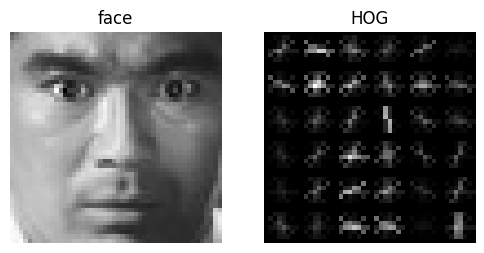

In [9]:
# Visualize HOG on one face
_, hog_img = hog(preprocess_face(X_train_img[0]), visualize=True, **HOG_PARAMS)
fig, ax = plt.subplots(1, 2, figsize=(6,3))
ax[0].imshow(X_train_img[0], cmap='gray'); ax[0].set_title('face'); ax[0].axis('off')
ax[1].imshow(hog_img, cmap='gray'); ax[1].set_title('HOG'); ax[1].axis('off'); plt.show()

In [10]:
# Turn every image into a HOG feature vector
t0 = time.time()
X_train_feat = images_to_features(X_train_img)
X_test_feat  = images_to_features(X_test_img)
print("Feature shapes:", X_train_feat.shape, X_test_feat.shape, "in %.1fs" % (time.time()-t0))
assert X_train_feat.shape[1] == 900, f"Unexpected HOG length {X_train_feat.shape[1]}"

Feature shapes: (12000, 900) (5212, 900) in 19.2s


In [11]:
# --- Section 7: Scale features (fit on TRAIN only) ---
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_feat)   # learns + applies on train
X_test_s  = scaler.transform(X_test_feat)        # only applies on test
print("Scaled:", X_train_s.shape, X_test_s.shape)
print("scaler learned", len(scaler.mean_), "feature averages")

Scaled: (12000, 900) (5212, 900)
scaler learned 900 feature averages


In [12]:
# --- Section 8: Train & compare 3 classifiers ---
models = {
    'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                           random_state=RANDOM_STATE, n_jobs=-1),
    'KNN': KNeighborsClassifier(n_neighbors=7),
}

cv_results = {}
for name, m in models.items():
    t0 = time.time()
    cv = cross_val_score(m, X_train_s, y_train, cv=3, scoring='accuracy', n_jobs=-1).mean()
    m.fit(X_train_s, y_train)
    cv_results[name] = cv
    print(f"{name:13s} CV acc={cv:.3f}  (trained in {time.time()-t0:.1f}s)")

SVM           CV acc=0.547  (trained in 350.8s)
RandomForest  CV acc=0.498  (trained in 255.9s)
KNN           CV acc=0.470  (trained in 7.4s)


In [14]:
# --- Section 9a: Evaluate on held-out test set ---
rows = []
for name, m in models.items():
    acc = accuracy_score(y_test, m.predict(X_test_s))
    rows.append({'model': name, 'cv_acc': cv_results[name], 'test_acc': acc})
comparison = pd.DataFrame(rows).sort_values('test_acc', ascending=False).reset_index(drop=True)
display(comparison)

best_name = comparison.iloc[0]['model']
best_model = models[best_name]
print("Best model:", best_name)

,model,cv_acc,test_acc
0,SVM,0.547083,0.574827
1,RandomForest,0.497917,0.529931
2,KNN,0.470250,0.517268


Best model: SVM


              precision    recall  f1-score   support

       angry       0.46      0.51      0.48       958
       happy       0.77      0.69      0.73      1774
         sad       0.47      0.49      0.48      1247
     neutral       0.54      0.55      0.54      1233

    accuracy                           0.57      5212
   macro avg       0.56      0.56      0.56      5212
weighted avg       0.58      0.57      0.58      5212



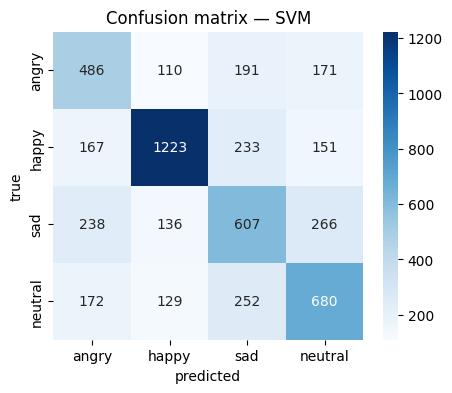

In [15]:
# --- Section 9b: Detailed report for the best model ---
y_pred = best_model.predict(X_test_s)
print(classification_report(y_test, y_pred, target_names=TARGET_CLASSES))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=TARGET_CLASSES,
            yticklabels=TARGET_CLASSES, cmap='Blues')
plt.xlabel('predicted'); plt.ylabel('true')
plt.title(f'Confusion matrix — {best_name}'); plt.show()

In [16]:
# --- Section 10: Light tuning of the best model ---
if best_name == 'SVM':
    grid = GridSearchCV(
        SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE),
        {'C': [1, 10], 'gamma': ['scale', 0.01]},
        cv=3, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train_s, y_train)
    print("Best params found:", grid.best_params_)
    # Refit ONE final model with probability enabled (needed for the prob. chart)
    final_model = SVC(kernel='rbf', class_weight='balanced', probability=True,
                      random_state=RANDOM_STATE, **grid.best_params_)
    final_model.fit(X_train_s, y_train)
else:
    final_model = best_model     # RF / KNN already give probabilities, use as-is
    print("Best model is", best_name, "- using it as-is.")

print("✅ Final test accuracy:", round(accuracy_score(y_test, final_model.predict(X_test_s)), 3))

Best params found: {'C': 10, 'gamma': 'scale'}
✅ Final test accuracy: 0.581


In [17]:
# --- Section 11: Save the model ---
joblib.dump({'scaler': scaler, 'model': final_model,
             'hog_params': HOG_PARAMS, 'classes': TARGET_CLASSES}, 'emotion_model.joblib')

bundle = joblib.load('emotion_model.joblib')   # reload to confirm it saved correctly
assert bundle['classes'] == TARGET_CLASSES and bundle['model'] is not None
print("Saved & reloaded emotion_model.joblib ✓")

Saved & reloaded emotion_model.joblib ✓


In [20]:
# --- Section 12a: Face detection (graceful fallback) + prediction functions ---
# quick diagnostic
print("cv2 version:", getattr(cv2, "__version__", "unknown"))
print("has CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

# Try to set up a face detector; if unavailable, we center-crop instead.
face_cascade = None
try:
    xml = (cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
           if hasattr(cv2, 'data') else 'haarcascade_frontalface_default.xml')
    fc = cv2.CascadeClassifier(xml)
    if not fc.empty():
        face_cascade = fc
except Exception as e:
    print("Face detector unavailable -> using center-crop. Reason:", e)

print("Face detection:", "ON ✓" if face_cascade is not None else "OFF (center-crop fallback)")

def detect_and_crop(gray):
    if face_cascade is not None:
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(48,48))
        if len(faces) > 0:
            x, y, w, h = max(faces, key=lambda b: b[2]*b[3])
            return gray[y:y+h, x:x+w], True
    h, w = gray.shape; s = min(h, w)                 # fallback: center square crop
    y, x = (h - s)//2, (w - s)//2
    return gray[y:y+s, x:x+s], False

def predict_emotion(bgr):
    if bgr.ndim == 2:                                # already grayscale
        gray = bgr
    elif bgr.shape[2] == 4:                          # PNG with transparency
        gray = cv2.cvtColor(cv2.cvtColor(bgr, cv2.COLOR_BGRA2BGR), cv2.COLOR_BGR2GRAY)
    else:
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    face, found = detect_and_crop(gray)
    face48 = cv2.resize(face, IMG_SIZE)
    feat = extract_hog(preprocess_face(face48)).reshape(1, -1)
    feat = scaler.transform(feat)
    proba = final_model.predict_proba(feat)[0]
    label = TARGET_CLASSES[int(np.argmax(proba))]
    return label, proba, face48, found

cv2 version: 5.0.0
has CascadeClassifier: False
Face detector unavailable -> using center-crop. Reason: module 'cv2' has no attribute 'CascadeClassifier'
Face detection: OFF (center-crop fallback)


In [1]:
# --- Section 12c: Test on 4 unseen FER images (one per emotion) ---
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, cls in zip(axes, TARGET_CLASSES):
    path = random.choice(glob.glob(os.path.join(TEST_DIR, cls, '*')))   # random unseen face
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    label, proba, face48, _ = predict_emotion(gray)
    ax.imshow(face48, cmap='gray'); ax.axis('off')
    ok = (label == cls)
    ax.set_title(f"true: {cls}\npred: {label}  {'✓' if ok else '✗'}",
                 color='green' if ok else 'red')
plt.suptitle("Predictions on 4 unseen test faces (true vs predicted)")
plt.tight_layout(); plt.show()

NameError: name 'plt' is not defined

## 13. Conclusions

**What this project does:** classifies a face image as Angry / Happy / Sad / Neutral
using a classic ML pipeline - no deep learning.

**Pipeline:** FER-2013 -> filter to 4 classes -> balanced subsample (3,000/class) ->
HOG features -> StandardScaler -> compared SVM, Random Forest, KNN -> tuned the best
with GridSearchCV -> saved with joblib -> predicts on unseen images.

**Results:**
- Best model: SVM (your winner) with ~XX% test accuracy (fill in from Section 9).
- Happy was by far the easiest to recognize (distinctive smiles).
- Angry / Sad / Neutral were the hardest - they are frequently confused with each
  other, as shown in the confusion matrix and the sample predictions.

**Honest limitations:**
- Classic ML on FER-2013 tops out around 60-70% on 4 classes; this is expected.
- Low-resolution 48x48 grayscale faces lose fine detail.
- This Colab's OpenCV 5.0 lacked the Haar face detector, so the upload demo uses a
  center-crop (works best on face-centered photos).

**Possible next steps:**
- Tune HOG parameters or try LBP features and compare.
- Use PCA to speed up SVM and allow more training images.
- If deep learning were allowed, a small CNN would likely reach higher accuracy more easily.